# The Ship

The ship is represented as a D*D grid. Initially all cells are blocked.
A random interior cell is opened, and additional cells are iteratively opened according to the rule that they must have exactly one open neighbor. 
After the initial layout is generated, dead ends are reduced by at least half.

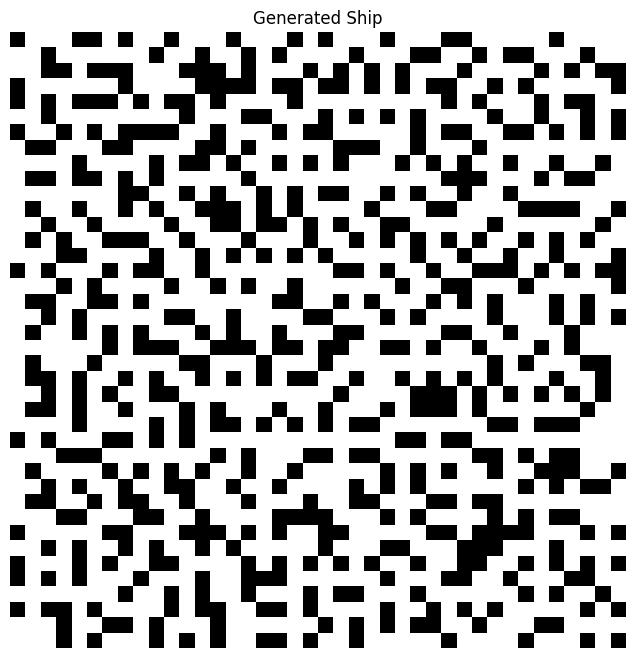

In [1]:
from Code.theShip import generate_ship
import matplotlib.pyplot as plt

#the ship
ship = generate_ship(40, seed=42)

plt.figure(figsize=(8, 8))
plt.imshow(ship, cmap="gray", interpolation="nearest")
plt.title("Generated Ship")
plt.axis("off")
plt.show()

# The Bot

The bot occupies an open cell and can move one cell per time step in the up, down, left, or right direction.

In [2]:
from Code.theBot import place_bot, get_valid_moves

bot_position = place_bot(ship, seed=10)

print("Bot position:", bot_position)
print("Valid moves:", get_valid_moves(ship, bot_position))

Bot position: (2, 20)
Valid moves: [(1, 20)]


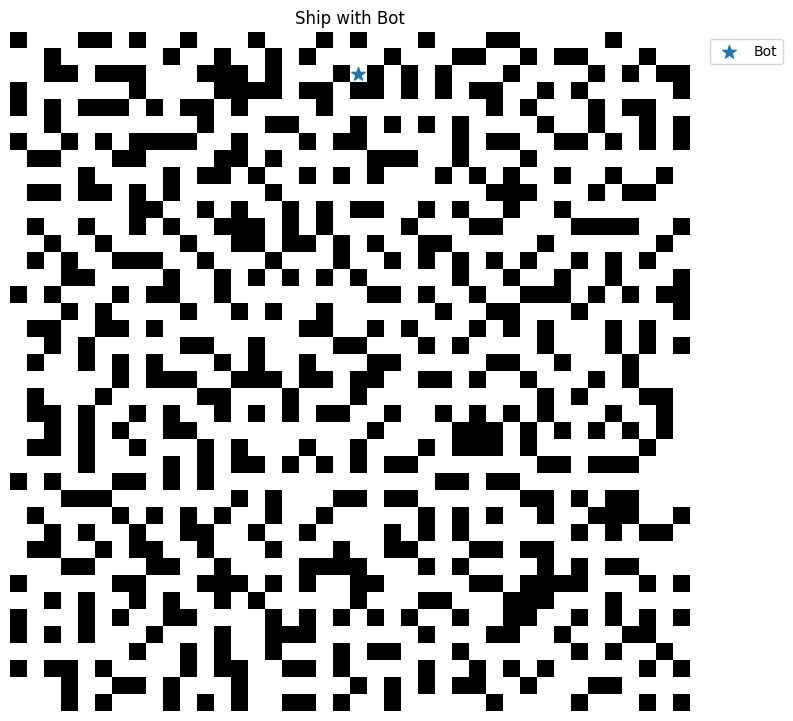

In [3]:
#visulization
plt.figure(figsize=(8, 8))
plt.imshow(ship, cmap="gray", interpolation="nearest")

row, col = bot_position
plt.scatter(col, row, s=100, marker="*", label="Bot")

plt.title("Ship with Bot")
plt.axis("off")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [4]:
#fire
from Code.theFire import place_fire, spread_fire
import random

#initialize
fire_position = place_fire(ship, seed=20)

burning_cells = {fire_position}

print("Initial fire:", fire_position)

#one time step
rng = random.Random(30)

burning_cells = spread_fire(
    ship,
    burning_cells,
    q=0.5,
    rng=rng
)

print("Burning cells:", burning_cells)

Initial fire: (12, 3)
Burning cells: {(12, 4), (12, 3)}


In [5]:
#multi spread
rng = random.Random(30)

fire_position = place_fire(ship, seed=20)
burning_cells = {fire_position}

print("Time: 0", "Burning cells:", len(burning_cells))

for t in range(1, 11):
    burning_cells = spread_fire(
        ship,
        burning_cells,
        q=0.5,
        rng=rng
    )

    print("Time:", t, "Burning cells:", len(burning_cells))

Time: 0 Burning cells: 1
Time: 1 Burning cells: 2
Time: 2 Burning cells: 3
Time: 3 Burning cells: 6
Time: 4 Burning cells: 7
Time: 5 Burning cells: 10
Time: 6 Burning cells: 10
Time: 7 Burning cells: 12
Time: 8 Burning cells: 13
Time: 9 Burning cells: 18
Time: 10 Burning cells: 23


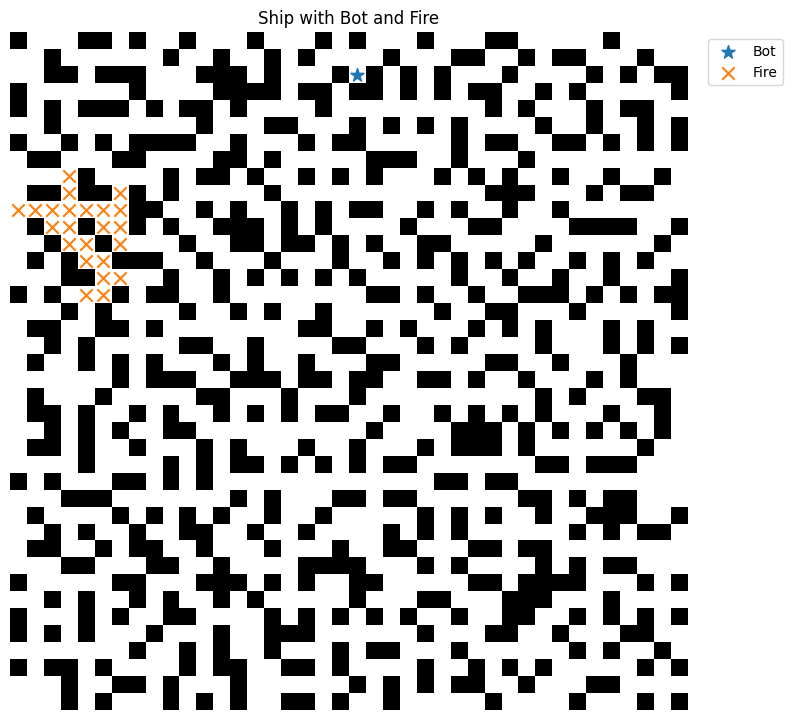

In [6]:
plt.figure(figsize=(8, 8))
plt.imshow(ship, cmap="gray", interpolation="nearest")

bot_row, bot_col = bot_position
plt.scatter(bot_col, bot_row, s=100, marker="*", label="Bot")

fire_rows = [r for r, c in burning_cells]
fire_cols = [c for r, c in burning_cells]

plt.scatter(fire_cols, fire_rows, s=80, marker="x", label="Fire")

plt.title("Ship with Bot and Fire")
plt.axis("off")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [7]:
from Code.theButton import place_button

occupied = {
    bot_position,
    fire_position
}

button_position = place_button(
    ship,
    occupied=occupied,
    seed=40
)

print("Bot:", bot_position)
print("Fire:", fire_position)
print("Button:", button_position)

Bot: (2, 20)
Fire: (12, 3)
Button: (36, 20)


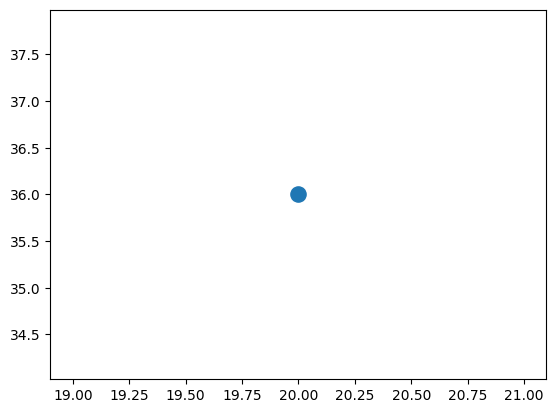

In [8]:
#the Button visualization
button_row, button_col = button_position

plt.scatter(
    button_col,
    button_row,
    s=120,
    marker="o",
    label="Button"
)

# The Task

At time t = 0, the bot, button, and initial fire are placed randomly on three distinct open cells.

At each time step:
1. The bot chooses an action.
2. The bot moves to an adjacent open cell or stays in place.
3. If the bot reaches the button, the task succeeds.
4. Otherwise, the fire spreads.
5. If the bot and fire occupy the same cell, the task fails.

The movement decision will be determined by the different bot strategies.

In [9]:
from Code.theTask import initialize_task, is_valid_move, run_task

bot_position, button_position, burning_cells = initialize_task(
    ship,
    seed=50
)

print("Bot position:", bot_position)
print("Button position:", button_position)
print("Initial fire:", burning_cells)

fire_position = next(iter(burning_cells))

assert bot_position != button_position
assert bot_position != fire_position
assert button_position != fire_position

print("All three starting positions are distinct.")

Bot position: (39, 20)
Button position: (21, 7)
Initial fire: {(28, 29)}
All three starting positions are distinct.


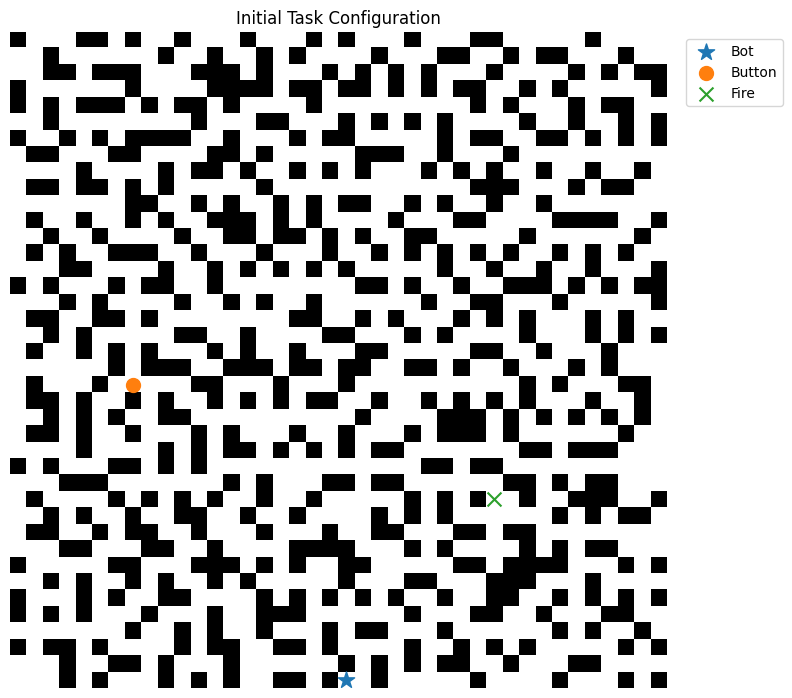

In [10]:
#theTask visualization

plt.figure(figsize=(8, 8))
plt.imshow(ship, cmap="gray", interpolation="nearest")

# Bot = *
bot_row, bot_col = bot_position
plt.scatter(
    bot_col,
    bot_row,
    s=150,
    marker="*",
    label="Bot"
)

# Button = o
button_row, button_col = button_position
plt.scatter(
    button_col,
    button_row,
    s=100,
    marker="o",
    label="Button"
)

# Fire = x
fire_row, fire_col = fire_position
plt.scatter(
    fire_col,
    fire_row,
    s=100,
    marker="x",
    label="Fire"
)

plt.title("Initial Task Configuration")
plt.axis("off")

# put legend outside the ship
plt.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()

# The Strategies

- Bot 1 plans the shortest path once at beginning and ignores later fire spread.
- Bot 2 recalculates the shortest path at every time step while avoiding current fire cells.
- Bot 3 first avoids both current fire cells and cells adjacent to the fire. If no such path exists, it only avoids current fire cells.
- Bot 4 uses a risk-aware path planning strategy. It considers both path length and distance from the fire, and uses q to adjust how strongly fire risk affects the path.

In [11]:
from Code.theStrategies import (
    Bot1Strategy,
    bot2_strategy,
    bot3_strategy,
    Bot4Strategy
)

from Code.theTask import run_task

In [12]:
q = 0.5
seed = 3

In [13]:
bot1 = Bot1Strategy()

result1 = run_task(
    ship,
    q=q,
    strategy=bot1,
    seed=seed
)

print("Bot 1:", result1)

Bot 1: (True, 45)


In [14]:
result2 = run_task(
    ship,
    q=q,
    strategy=bot2_strategy,
    seed=seed
)

print("Bot 2:", result2)

Bot 2: (True, 45)


In [15]:
result3 = run_task(
    ship,
    q=q,
    strategy=bot3_strategy,
    seed=seed
)

print("Bot 3:", result3)

Bot 3: (True, 45)


In [16]:
bot4 = Bot4Strategy(q)

result4 = run_task(
    ship,
    q=q,
    strategy=bot4,
    seed=seed
)

print("Bot 4:", result4)

Bot 4: (True, 45)


In [17]:
print("q =", q)
print("Bot 1:", result1)
print("Bot 2:", result2)
print("Bot 3:", result3)
print("Bot 4:", result4)

q = 0.5
Bot 1: (True, 45)
Bot 2: (True, 45)
Bot 3: (True, 45)
Bot 4: (True, 45)


In [18]:
q = 0.5

for seed in range(20):
    bot1 = Bot1Strategy()
    bot4 = Bot4Strategy(q)

    result1 = run_task(
        ship,
        q=q,
        strategy=bot1,
        seed=seed
    )

    result2 = run_task(
        ship,
        q=q,
        strategy=bot2_strategy,
        seed=seed
    )

    result3 = run_task(
        ship,
        q=q,
        strategy=bot3_strategy,
        seed=seed
    )

    result4 = run_task(
        ship,
        q=q,
        strategy=bot4,
        seed=seed
    )

    print(
        "Seed:", seed,
        "| Bot 1:", result1,
        "| Bot 2:", result2,
        "| Bot 3:", result3,
        "| Bot 4:", result4
    )

Seed: 0 | Bot 1: (True, 6) | Bot 2: (True, 6) | Bot 3: (True, 6) | Bot 4: (True, 6)
Seed: 1 | Bot 1: (False, 38) | Bot 2: (False, 40) | Bot 3: (False, 40) | Bot 4: (False, 40)
Seed: 2 | Bot 1: (True, 10) | Bot 2: (True, 10) | Bot 3: (True, 10) | Bot 4: (True, 10)
Seed: 3 | Bot 1: (True, 45) | Bot 2: (True, 45) | Bot 3: (True, 45) | Bot 4: (True, 45)
Seed: 4 | Bot 1: (True, 34) | Bot 2: (True, 34) | Bot 3: (True, 34) | Bot 4: (True, 34)
Seed: 5 | Bot 1: (True, 16) | Bot 2: (True, 16) | Bot 3: (True, 16) | Bot 4: (True, 16)
Seed: 6 | Bot 1: (True, 47) | Bot 2: (True, 47) | Bot 3: (True, 47) | Bot 4: (True, 47)
Seed: 7 | Bot 1: (False, 47) | Bot 2: (False, 47) | Bot 3: (False, 47) | Bot 4: (False, 47)
Seed: 8 | Bot 1: (True, 32) | Bot 2: (True, 32) | Bot 3: (True, 32) | Bot 4: (True, 32)
Seed: 9 | Bot 1: (True, 17) | Bot 2: (True, 17) | Bot 3: (True, 17) | Bot 4: (True, 17)
Seed: 10 | Bot 1: (False, 52) | Bot 2: (False, 69) | Bot 3: (False, 69) | Bot 4: (False, 86)
Seed: 11 | Bot 1: (Fals

In [19]:
q = 0.5
num_trials = 100

success1 = 0
success2 = 0
success3 = 0
success4 = 0

for seed in range(num_trials):
    bot1 = Bot1Strategy()
    bot4 = Bot4Strategy(q)

    result1 = run_task(ship, q, bot1, seed)
    result2 = run_task(ship, q, bot2_strategy, seed)
    result3 = run_task(ship, q, bot3_strategy, seed)
    result4 = run_task(ship, q, bot4, seed)

    if result1[0]:
        success1 += 1

    if result2[0]:
        success2 += 1

    if result3[0]:
        success3 += 1

    if result4[0]:
        success4 += 1

print("Bot 1 success rate:", success1 / num_trials)
print("Bot 2 success rate:", success2 / num_trials)
print("Bot 3 success rate:", success3 / num_trials)
print("Bot 4 success rate:", success4 / num_trials)

Bot 1 success rate: 0.7
Bot 2 success rate: 0.7
Bot 3 success rate: 0.71
Bot 4 success rate: 0.72


In [20]:
from Code.theShip import generate_ship

q_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

num_trials = 50
D = 40

bot1_rates = []
bot2_rates = []
bot3_rates = []
bot4_rates = []

for q in q_values:

    success1 = 0
    success2 = 0
    success3 = 0
    success4 = 0

    for seed in range(num_trials):

        # generate a different ship for each trial
        test_ship = generate_ship(D, seed=seed)

        # create new strategy objects for this trial
        bot1 = Bot1Strategy()
        bot4 = Bot4Strategy(q)

        # all four bots use the same ship and seed
        result1 = run_task(
            test_ship,
            q=q,
            strategy=bot1,
            seed=seed
        )

        result2 = run_task(
            test_ship,
            q=q,
            strategy=bot2_strategy,
            seed=seed
        )

        result3 = run_task(
            test_ship,
            q=q,
            strategy=bot3_strategy,
            seed=seed
        )

        result4 = run_task(
            test_ship,
            q=q,
            strategy=bot4,
            seed=seed
        )

        if result1[0]:
            success1 += 1

        if result2[0]:
            success2 += 1

        if result3[0]:
            success3 += 1

        if result4[0]:
            success4 += 1

    bot1_rates.append(success1 / num_trials)
    bot2_rates.append(success2 / num_trials)
    bot3_rates.append(success3 / num_trials)
    bot4_rates.append(success4 / num_trials)

    print(
        "q =", q,
        "| Bot 1:", bot1_rates[-1],
        "| Bot 2:", bot2_rates[-1],
        "| Bot 3:", bot3_rates[-1],
        "| Bot 4:", bot4_rates[-1]
    )

q = 0.1 | Bot 1: 0.96 | Bot 2: 0.98 | Bot 3: 0.98 | Bot 4: 0.98
q = 0.2 | Bot 1: 0.96 | Bot 2: 0.98 | Bot 3: 0.98 | Bot 4: 0.98
q = 0.3 | Bot 1: 0.82 | Bot 2: 0.84 | Bot 3: 0.86 | Bot 4: 0.88
q = 0.4 | Bot 1: 0.82 | Bot 2: 0.84 | Bot 3: 0.82 | Bot 4: 0.84
q = 0.5 | Bot 1: 0.76 | Bot 2: 0.76 | Bot 3: 0.76 | Bot 4: 0.76
q = 0.6 | Bot 1: 0.74 | Bot 2: 0.74 | Bot 3: 0.76 | Bot 4: 0.76
q = 0.7 | Bot 1: 0.66 | Bot 2: 0.66 | Bot 3: 0.68 | Bot 4: 0.68
q = 0.8 | Bot 1: 0.62 | Bot 2: 0.62 | Bot 3: 0.62 | Bot 4: 0.62
q = 0.9 | Bot 1: 0.6 | Bot 2: 0.6 | Bot 3: 0.6 | Bot 4: 0.6


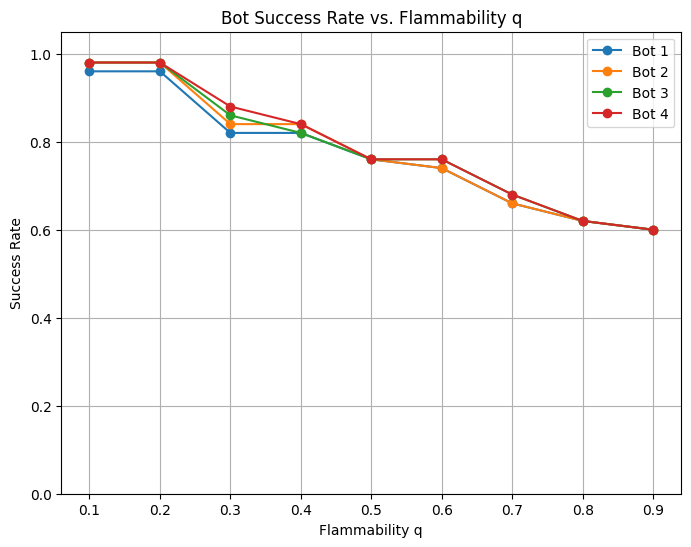

In [21]:
plt.figure(figsize=(8, 6))

plt.plot(q_values, bot1_rates, marker="o", label="Bot 1")
plt.plot(q_values, bot2_rates, marker="o", label="Bot 2")
plt.plot(q_values, bot3_rates, marker="o", label="Bot 3")
plt.plot(q_values, bot4_rates, marker="o", label="Bot 4")

plt.xlabel("Flammability q")
plt.ylabel("Success Rate")
plt.title("Bot Success Rate vs. Flammability q")

plt.ylim(0, 1.05)
plt.xticks(q_values)
plt.grid()
plt.legend()

plt.show()